C:\Users\henna\anaconda3\Lib\site-packages\xarray\coding\times.py:254: RuntimeWarning: invalid value encountered in cast
  flat_num_dates_ns_int = (flat_num_dates * _NS_PER_TIME_DELTA[delta]).astype(
C:\Users\henna\anaconda3\Lib\site-packages\xarray\coding\times.py:254: RuntimeWarning: invalid value encountered in cast
  flat_num_dates_ns_int = (flat_num_dates * _NS_PER_TIME_DELTA[delta]).astype(


<xarray.Dataset>
Dimensions:            (time_counter: 348, lon: 401, lat: 241, bnds: 2)
Coordinates:
  * time_counter       (time_counter) datetime64[ns] 1993-01-16 ... 2021-12-1...
  * lon                (lon) float64 20.0 20.25 20.5 20.75 ... 119.5 119.8 120.0
  * lat                (lat) float64 -30.0 -29.75 -29.5 ... 29.5 29.75 30.0
Dimensions without coordinates: bnds
Data variables:
    somxl030           (time_counter, lat, lon) float32 ...
    time_counter_bnds  (time_counter, bnds) datetime64[ns] ...
Attributes:
    CDI:          Climate Data Interface version 1.9.9rc1 (https://mpimet.mpg...
    Conventions:  CF-1.4
    history:      Sun Jun 30 16:08:12 2024: cdo remapbil,same_as_era5_grid ml...
    source:       ORAS5 - backward extension (ECMWF)
    institution:  European Centre for Medium-Range Weather Forecasts
    NCO:          netCDF Operators version 4.9.2 (Homepage = http://nco.sf.ne...
    title:        Monthly mean 2D fields
    reference:    https://www.ecmwf.int/e

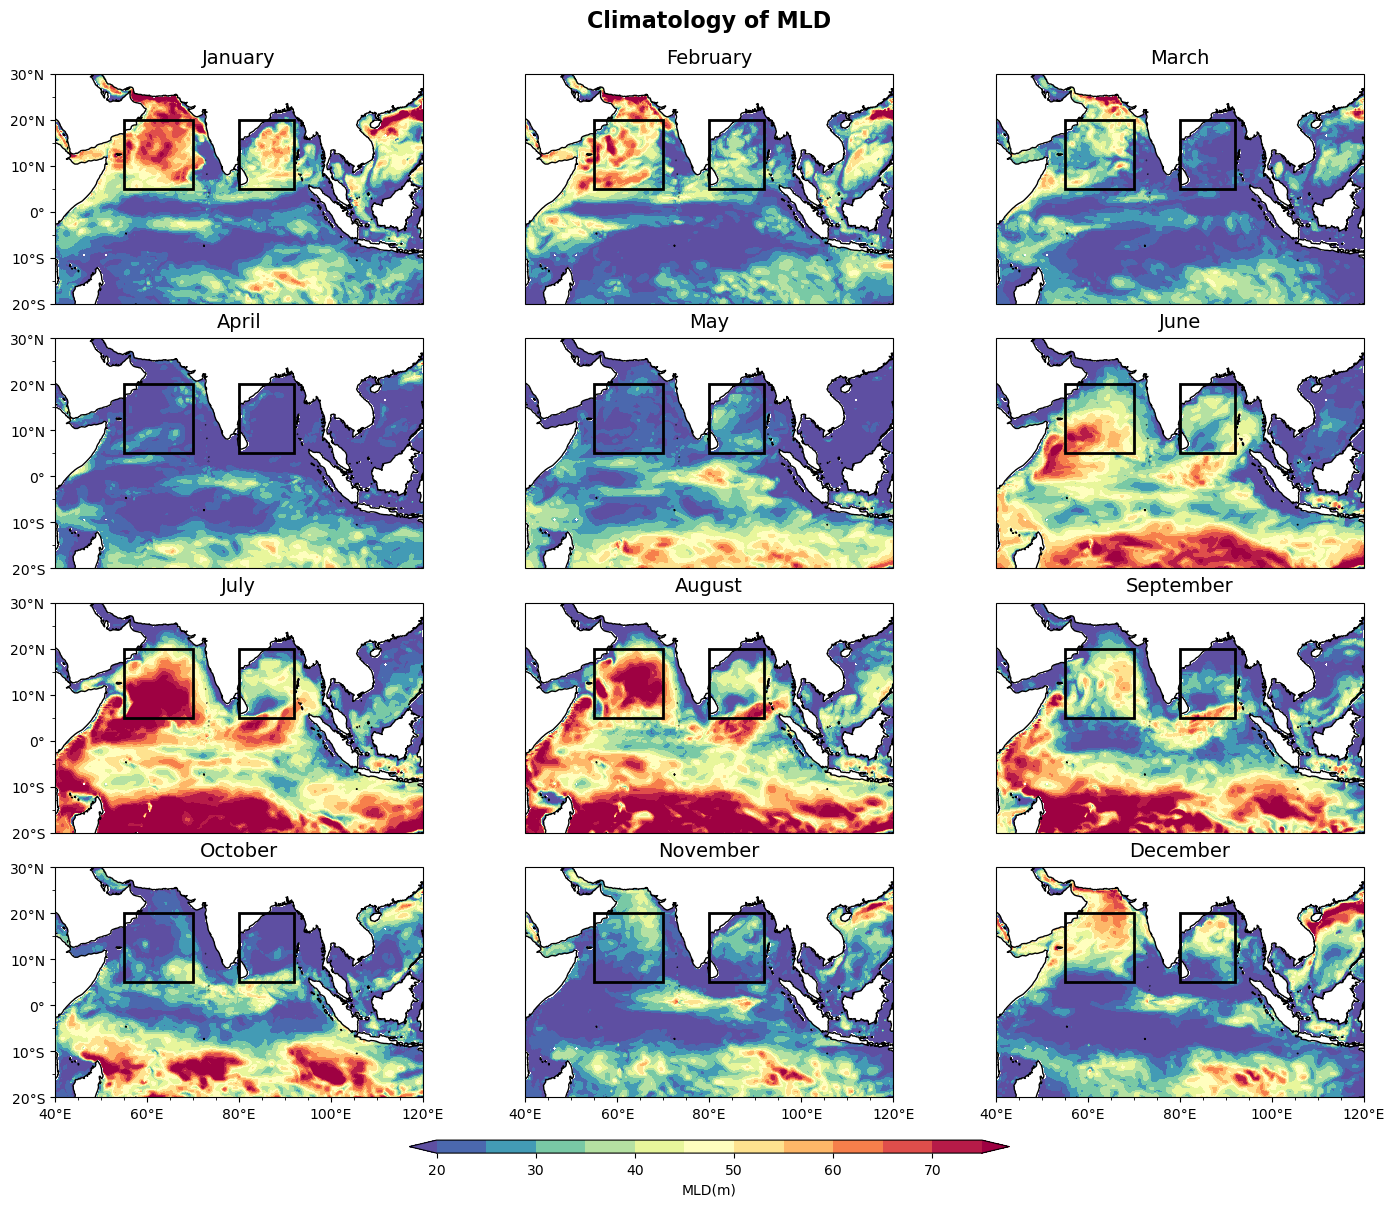

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import calendar
import cartopy.mpl.ticker as cticker
import calendar
from matplotlib.patches import Rectangle
from matplotlib.ticker import MultipleLocator
ds=xr.open_dataset('mldgrid.nc')
#print(ds)
ds = ds.sel(time_counter= slice('1993','2021'),lat=slice(-20,30),lon=slice(40,120))
mld=ds['somxl030'].values
#climatology
climatology= ds.groupby('time_counter.month').mean(dim='time_counter')
#print(climatology)
clevels=np.arange(20,80,5)

fig,axs = plt.subplots(nrows = 4, ncols = 3, subplot_kw = {'projection':ccrs.PlateCarree()}, figsize = (15,13))
plt.subplots_adjust(left=0.05, right=0.95, bottom=0.113, top=0.9, wspace=0.15, hspace=0.15)
axs = axs.flatten()
for j in range(12):
    cf = axs[j].contourf(ds['lon'], ds['lat'],ds['somxl030'][j],cmap='Spectral_r',levels=clevels,extend='both', transform=ccrs.PlateCarree())
    axs[j].coastlines()
    # Define the xticks for longitude
    if j >= 9:
       lon_range = np.arange(np.floor(ds['lon'].min()), np.ceil(ds['lon'].max()) + 1, 20)
       axs[j].set_xticks(lon_range, crs=ccrs.PlateCarree())
       lon_formatter = cticker.LongitudeFormatter()
       axs[j].xaxis.set_major_formatter(lon_formatter)
       axs[j].xaxis.set_minor_locator(MultipleLocator(5))
    # Define the yticks for latitude
    if j%3==0:
       lat_range = np.arange(np.floor(ds['lat'].min()), np.ceil(ds['lat'].max()) + 1,10)
       axs[j].set_yticks(lat_range, crs=ccrs.PlateCarree())
       lat_formatter = cticker.LatitudeFormatter()
       axs[j].yaxis.set_major_formatter(lat_formatter)
       axs[j].yaxis.set_minor_locator(MultipleLocator(5))
    #add month name to the plot
    month_name=calendar.month_name[j+1]
    axs[j].text(0.5,1.05,month_name,ha='center',transform=axs[j].transAxes,fontsize=14)
plt.suptitle(('Climatology of MLD'),fontsize=16,fontweight='bold',y=0.95,)
plt.minorticks_on()
box1=[55,70,5,20]
box2=[80,92,5,20]
for i in range(12):
    axs[i].add_patch(Rectangle((box1[0],box1[2]),box1[1]-box1[0],box1[3]-box1[2],fill=None,edgecolor='black',linewidth=2))
    axs[i].add_patch(Rectangle((box2[0],box2[2]),box2[1]-box2[0],box2[3]-box2[2],fill=None,edgecolor='black',linewidth=2))


# Define the subplot axis for the colorbar
cbar_ax = fig.add_axes([0.3, 0.07, 0.4, 0.01])
cbar = fig.colorbar(cf, cax=cbar_ax, orientation='horizontal', label='MLD(m)')
cbar.ax.xaxis.set_label_coords(0.5, -2.3)


plt.show()